In [ ]:
from typing import List
import numpy as np
import random
def num_differences(x_1: List[float], x_2: List[float]) -> int:
    assert len(x_1) == len(x_2), 'wektory roznej dlugosci'
    return len([x for x, y in zip(x_1, x_2) if x != y ])

assert num_differences([1, 2, 3], [2, 1, 3]) == 2
assert num_differences([1, 2], [1, 2]) == 0

try:
    num_differences([1,2], [1])
except AssertionError as e:
    print(e)

def cluster_means(k: int, inputs: List[list[float]], assignments: List[int]) -> List[List[float]]:
    clusters = [[] for i in range(k)]
    for vector, k_i in zip(inputs, assignments):
        clusters[k_i].append(vector)
    return [np.mean(cluster, axis=0).tolist() if cluster else random.choice(inputs) for cluster in clusters]


wektory roznej dlugosci


In [17]:
import itertools
import tqdm
import math
class Kmeans:
    def __init__(self, k:int) -> None:
        self.k = k
        self.means = None 

    def classify(self, input: List[float]) -> int:
        """zwraca indeks klastra najblizeszego inputowi"""
        return(min(range(self.k), key= lambda i: math.dist(input, self.means[i])))

    def train(self, inputs: List[List[float]]) -> None:
            
            assignments = [-1 for _ in range(len(inputs))]
            self.means = random.sample(inputs, self.k)
            
            with tqdm.tqdm(itertools.count()) as t:
                for _ in t:
                    new_assignments = [self.classify(input) for input in inputs]

                    num_changed = num_differences(new_assignments, assignments)                
                    if num_changed == 0:
                        return 
                    
                    assignments = new_assignments
                    self.means = cluster_means(self.k, inputs, assignments)
                    t.set_description(f"changed: {num_changed} / {len(inputs)}")

In [23]:
inputs: List[List[float]] = [[-14,-5],[13,13],[20,23],[-19,-11],[-9,-16],[21,27],[-49,15],[26,13],[-46,5],[-34,-1],[11,15],[-49,0],[-22,-16],[19,28],[-12,-8],[-13,-19],[-41,8],[-11,-6],[-25,-9],[-18,-3]]


In [ ]:

random.seed(12)                   # so you get the same results as me
clusterer = Kmeans(k=3)
clusterer.train(inputs)
means = sorted(clusterer.means)   # sort for the unit test

assert len(means) == 3

# Check that the means are close to what we expect.
assert math.dist(means[0], [-44, 5]) < 1
assert math.dist(means[1], [-16, -10]) < 1
assert math.dist(means[2], [18, 20]) < 1


changed: 4 / 20: : 4it [00:00, 1282.86it/s]


[[-43.8, 5.4],
 [-15.88888888888889, -10.333333333333334],
 [18.333333333333332, 19.833333333333332]]

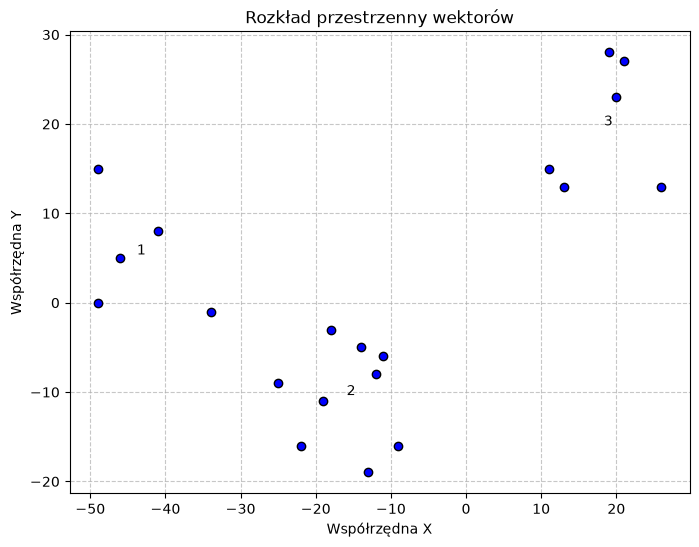

In [30]:
import matplotlib.pyplot as plt


x = [point[0] for point in inputs]
y = [point[1] for point in inputs]


plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', edgecolor='black', zorder=2)
for i, mean in enumerate(means,1):
    plt.text(mean[0],mean[1], f'{i}')

plt.title("Rozkład przestrzenny wektorów")
plt.xlabel("Współrzędna X")
plt.ylabel("Współrzędna Y")
plt.grid(True, linestyle='--', alpha=0.7, zorder=1)


plt.show()

changed: 3 / 20: : 6it [00:00, 1385.02it/s]


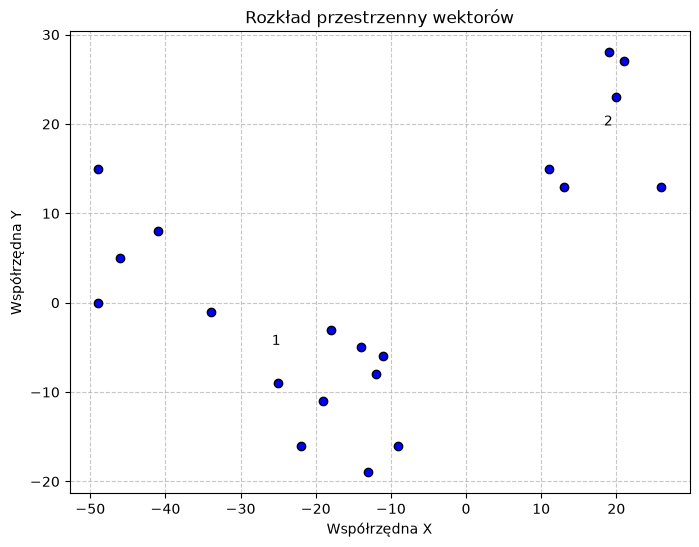

In [31]:
random.seed(12)                   # so you get the same results as me
clusterer = Kmeans(k=2)
clusterer.train(inputs)
means = sorted(clusterer.means)   # sort for the unit test

import matplotlib.pyplot as plt


x = [point[0] for point in inputs]
y = [point[1] for point in inputs]


plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', edgecolor='black', zorder=2)
for i, mean in enumerate(means,1):
    plt.text(mean[0],mean[1], f'{i}')

plt.title("Rozkład przestrzenny wektorów")
plt.xlabel("Współrzędna X")
plt.ylabel("Współrzędna Y")
plt.grid(True, linestyle='--', alpha=0.7, zorder=1)


plt.show()

changed: 20 / 20: : 1it [00:00, 965.32it/s]
changed: 3 / 20: : 7it [00:00, 2615.83it/s]
changed: 1 / 20: : 2it [00:00, 2448.51it/s]
changed: 3 / 20: : 2it [00:00, 3675.99it/s]
changed: 1 / 20: : 2it [00:00, 4175.51it/s]
changed: 20 / 20: : 1it [00:00, 3663.15it/s]
changed: 1 / 20: : 2it [00:00, 4108.04it/s]
changed: 1 / 20: : 2it [00:00, 1599.96it/s]
changed: 1 / 20: : 2it [00:00, 2967.32it/s]
changed: 1 / 20: : 2it [00:00, 4046.60it/s]
changed: 1 / 20: : 2it [00:00, 3930.93it/s]
changed: 2 / 20: : 2it [00:00, 3867.50it/s]
changed: 20 / 20: : 1it [00:00, 3536.51it/s]
changed: 20 / 20: : 1it [00:00, 3019.66it/s]
changed: 1 / 20: : 2it [00:00, 2853.27it/s]
changed: 20 / 20: : 1it [00:00, 3086.32it/s]
changed: 20 / 20: : 1it [00:00, 3302.60it/s]
changed: 20 / 20: : 1it [00:00, 2770.35it/s]
changed: 20 / 20: : 1it [00:00, 3155.98it/s]
changed: 20 / 20: : 1it [00:00, 3134.76it/s]


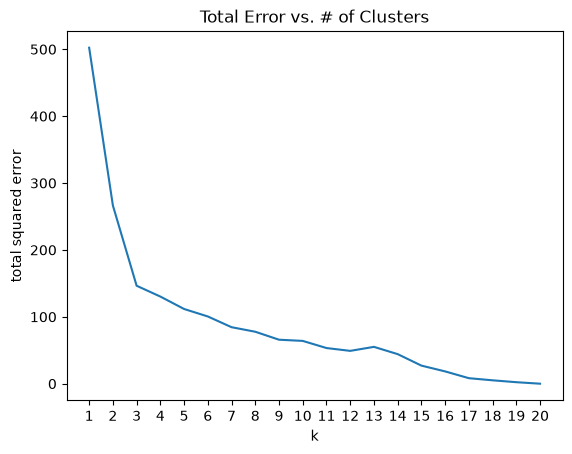

In [35]:
def squared_clustering_errors(inputs: List[List[float]], k: int) -> float:
        """finds the total squared error from k-means clustering the inputs"""
        clusterer = Kmeans(k)
        clusterer.train(inputs)
        means = clusterer.means
        assignments = [clusterer.classify(input) for input in inputs]
    
        return sum(math.dist(input, means[cluster])
                   for input, cluster in zip(inputs, assignments))
    
    
ks = range(1, len(inputs) + 1)
errors = [squared_clustering_errors(inputs, k) for k in ks]

plt.plot(ks, errors)
plt.xticks(ks)
plt.xlabel("k")
plt.ylabel("total squared error")
plt.title("Total Error vs. # of Clusters")
plt.show()

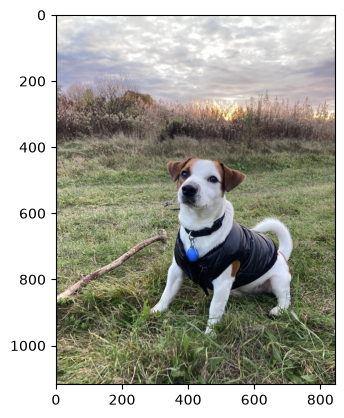

In [45]:
image_path = r"/Users/ignacyboczula/Desktop/Data_science_Joel_Grus/chapter_20/image.jpg"
import matplotlib.image as mpimg
img = mpimg.imread(image_path) 
img = img[:, :, :3]
top_row = img[0]
top_lef_pixel = top_row[0]
top_lef_pixel
plt.imshow(img)

In [49]:
pixels = [pixel.tolist() for row in img for pixel in row]

clusterer = Kmeans(5)
clusterer.train(pixels)   

def recolor(pixel: List[float]) -> List[float]:
    cluster = clusterer.classify(pixel)        # index of the closest cluster
    return clusterer.means[cluster]            # mean of the closest cluster

new_img = [[recolor(pixel) for pixel in row]   # recolor this row of pixels
            for row in img]                     # for each row in the image



changed: 5 / 943592: : 68it [00:44,  1.54it/s]    


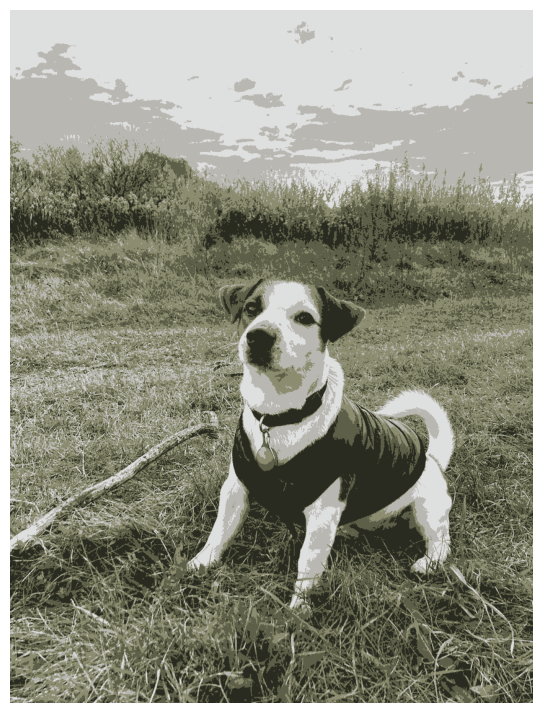

In [50]:
plt.figure(figsize=(16,9))
plt.imshow(new_img)
plt.axis('off')
plt.show()